# Análise Exploratória dos Dados (EDA) — Consumo Térmico (*Heat Demand*)
**Projeto Prático 4:** Previsão do Consumo Energético de Edifícios para Apoio à Gestão Inteligente  
**Unidade Curricular:** Redes Neuronais e Aprendizagem Profunda (UBI — 2026/2027)

---

### Objetivo deste Notebook
Este notebook realiza a **Análise Exploratória dos Dados (Ponto 4.1)** sobre os ficheiros de consumo térmico (*heat demand*) dos três edifícios universitários disponibilizados no dataset *E-LAND* (Zenodo):
* **Edifício ABR** (`UVTgv_heat_ABR_2019_2020.csv`)
* **Edifício C** (`UVTgv_heat_C_2019_2020.csv`)
* **Edifício ICSTM** (`UVTgv_heat_demand_building_ICSTM_2019.csv`)

*(Nota: "heat demand" corresponde à procura/consumo de energia térmica para aquecimento dos edifícios, medida em kWh/kW horários).*

Ao longo deste documento cobrimos todos os requisitos exigidos no enunciado:
1. Carregamento automático (com deteção inteligente do caminho dos ficheiros) e verificação do **número de registos**.
2. Identificação das **variáveis de consumo e unidades**.
3. Análise de **distribuição e variabilidade** (estatísticas descritivas, histogramas e boxplots).
4. Deteção de **valores em falta ou inconsistentes** (análise de `NaN`, valores negativos e anomalias de zeros contínuos).
5. **Evolução temporal** ao longo dos anos de 2019 e 2020.
6. Identificação de **padrões diários, semanais e sazonais** (heatmaps e perfis horários/mensais).
7. Caracterização de **períodos de consumo elevado e reduzido**.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')
plt.rcParams['figure.dpi'] = 120

def localizar_ficheiro(nome_ficheiro: str) -> Path:
    """Procura o CSV na pasta atual ou nas pastas do projeto (dataset/UVTgv_OD/demand)."""
    candidatos = [
        Path(nome_ficheiro),
        Path('../../dataset/UVTgv_OD/demand') / nome_ficheiro,
        Path('dataset/UVTgv_OD/demand') / nome_ficheiro,
    ]
    for caminho in candidatos:
        if caminho.exists():
            return caminho.resolve()
    for p in Path('.').resolve().parents:
        encontrados = list(p.rglob(nome_ficheiro))
        if encontrados:
            return encontrados[0]
    raise FileNotFoundError(f"Não foi possível encontrar '{nome_ficheiro}'. Verifica a localização dos CSVs.")

ficheiros = {
    'ABR': 'UVTgv_heat_ABR_2019_2020.csv',
    'C': 'UVTgv_heat_C_2019_2020.csv',
    'ICSTM': 'UVTgv_heat_demand_building_ICSTM_2019.csv',
}

dfs = {}
for edificio, nome in ficheiros.items():
    caminho = localizar_ficheiro(nome)
    df = pd.read_csv(caminho, sep=';')
    df['datetime_base'] = pd.date_range(start='2019-01-01 00:00:00', periods=len(df), freq='h')
    df['mes'] = df['datetime_base'].dt.month
    df['dia_semana'] = df['datetime_base'].dt.dayofweek
    df['hora'] = df['datetime_base'].dt.hour
    df['fim_de_semana'] = df['dia_semana'].isin([5, 6])
    dfs[edificio] = df
    print(f"[OK] {edificio:5s} -> {len(df)} registos | Colunas: {[c for c in df.columns if 'heat' in c]} | Caminho: {caminho}")

[OK] ABR   -> 8760 registos | Colunas: ['heat_ABR_2019', 'heat_ABR_2020'] | Caminho: C:\Programming\Redes\Energy_Consumption_Prediction\trabalho\ricardo\UVTgv_heat_ABR_2019_2020.csv
[OK] C     -> 8760 registos | Colunas: ['heat_C_2019', 'heat_C_2020'] | Caminho: C:\Programming\Redes\Energy_Consumption_Prediction\trabalho\ricardo\UVTgv_heat_C_2019_2020.csv
[OK] ICSTM -> 8760 registos | Colunas: ['heat_ICSTM_2019', 'heat_ICSTM_2020'] | Caminho: C:\Programming\Redes\Energy_Consumption_Prediction\trabalho\ricardo\UVTgv_heat_demand_building_ICSTM_2019.csv


---
## 1. Estrutura dos Dados, Variáveis e Estatísticas Descritivas

### Principais Observações:
* **Número de Registos:** Cada ficheiro contém exatamente **8.760 registos horários** ($365 \text{ dias} \times 24 \text{ horas}$), sem coluna explícita de timestamp no CSV original (os registos estão ordenados sequencialmente desde `01-01 00:00` até `31-12 23:00`).
* **Variáveis e Unidades:** Apesar de o ficheiro do ICSTM se chamar `..._ICSTM_2019.csv`, **todos os três ficheiros contêm duas colunas** correspondentes aos anos de **2019** e **2020** (ex.: `heat_ICSTM_2019` e `heat_ICSTM_2020`). Os valores representam a procura térmica horária (*heat demand*, expressa em **kWh** / potência média horária em **kW**).
* **Comparação de Escala entre Edifícios:**
  * **ABR** é o edifício com maior consumo térmico (média de ~116,3 kWh em 2019 e pico máximo de ~599,7 kWh).
  * **C** apresenta um consumo intermédio (média de ~72,3 kWh em 2019 e máximo de ~345,0 kWh).
  * **ICSTM** tem o menor consumo térmico dos três (média de ~43,5 kWh em 2019 e máximo de ~224,1 kWh).
* **Assimetria (Variabilidade):** Em todos os edifícios, o desvio padrão é ligeiramente superior à média e a mediana (percentil 50%) é cerca de metade da média. Isto indica uma **distribuição fortemente assimétrica à direita**, típica de sistemas de aquecimento que operam com valores baixos durante grande parte do ano e atingem picos elevados no inverno.

In [ ]:
resumo_stats = []

for edificio, df in dfs.items():
    cols_heat = [c for c in df.columns if 'heat' in c]
    for col in cols_heat:
        s = df[col]
        resumo_stats.append({
            'Edifício': edificio,
            'Variável': col,
            'Registos': len(s),
            'Média': s.mean(),
            'Desvio Padrão': s.std(),
            'Mínimo': s.min(),
            'Q25 (25%)': s.quantile(0.25),
            'Mediana (50%)': s.median(),
            'Q75 (75%)': s.quantile(0.75),
            'Máximo': s.max()
        })

df_stats = pd.DataFrame(resumo_stats).round(2)
display(df_stats)

,Edifício,Variável,Registos,Média,Desvio Padrão,Mínimo,Q25 (25%),Mediana (50%),Q75 (75%),Máximo
0,ABR,heat_ABR_2019,8760,116.34,120.25,0.00,22.41,57.25,207.69,599.66
1,ABR,heat_ABR_2020,8760,107.25,119.51,2.89,15.57,38.37,195.72,597.36
2,C,heat_C_2019,8760,72.25,73.68,0.00,14.23,37.08,123.09,345.00
3,C,heat_C_2020,8760,66.61,73.31,1.80,9.90,24.23,115.79,343.67
4,ICSTM,heat_ICSTM_2019,8760,43.48,44.94,0.00,8.38,21.40,77.62,224.12
5,ICSTM,heat_ICSTM_2020,8760,40.08,44.66,1.08,5.82,14.34,73.15,223.26


---
## 2. Verificação de Valores em Falta ou Inconsistentes

Uma análise rigorosa da qualidade dos dados revela dois pontos importantes para o relatório e para a etapa seguinte (Preparação dos Dados — 4.2):
1. **Ausência de `NaN` e Valores Negativos:** Nenhuma das séries apresenta valores nulos (`NaN`) ou negativos (`< 0`), o que confirma a integridade estrutural dos ficheiros.
2. **Anomalia de Zeros em Julho de 2019 (`744 horas`):** Em **todos os três edifícios**, existem exatamente **744 registos iguais a `0.00` em 2019**, que correspondem integralmente às $31 \text{ dias} \times 24 \text{ horas} = 744 \text{ horas}$ do mês de **julho de 2019**! Em 2020, pelo contrário, não existem zeros absolutos (o sistema mantém um consumo basal mínimo de água quente sanitária/manutenção térmica mesmo no verão). Esta paragem total em julho de 2019 pode dever-se a manutenção da central térmica do campus ou falha de registo nos sensores — um ponto excelente para destacar no relatório!

In [3]:
qualidade = []
for edificio, df in dfs.items():
    cols_heat = [c for c in df.columns if 'heat' in c]
    for col in cols_heat:
        s = df[col]
        meses_zero = df.loc[s == 0, 'mes'].unique().tolist()
        qualidade.append({
            'Edifício': edificio,
            'Variável': col,
            'Valores Nulos (NaN)': int(s.isnull().sum()),
            'Valores Negativos (<0)': int((s < 0).sum()),
            'Registos Iguais a Zero': int((s == 0).sum()),
            'Meses com Zeros': meses_zero if meses_zero else 'Nenhum'
        })

display(pd.DataFrame(qualidade))

,Edifício,Variável,Valores Nulos (NaN),Valores Negativos (<0),Registos Iguais a Zero,Meses com Zeros
0,ABR,heat_ABR_2019,0,0,744,[7]
1,ABR,heat_ABR_2020,0,0,0,Nenhum
2,C,heat_C_2019,0,0,744,[7]
3,C,heat_C_2020,0,0,0,Nenhum
4,ICSTM,heat_ICSTM_2019,0,0,744,[7]
5,ICSTM,heat_ICSTM_2020,0,0,0,Nenhum


---
## 3. Evolução do Consumo ao Longo do Tempo (2019 vs. 2020)

Ao visualizar as séries temporais completas (e a respetiva média móvel semanal de 168 horas para suavizar o ruído diário), observa-se claramente:
* **Forte Sazonalidade Anual:** O consumo atinge o máximo entre **janeiro e março** e volta a subir acentuadamente a partir de **outubro até dezembro** (meses frios). Entre **maio e setembro**, o consumo cai para valores residuais.
* **Diferença entre 2019 e 2020:** O consumo médio em 2020 é ligeiramente inferior ao de 2019 nos três edifícios (redução de ~7,8% em todos os edifícios), o que reflete quer variações climáticas anuais, quer a redução de ocupação/atividade presencial no campus universitário durante o ano de 2020 (pandemia COVID-19).

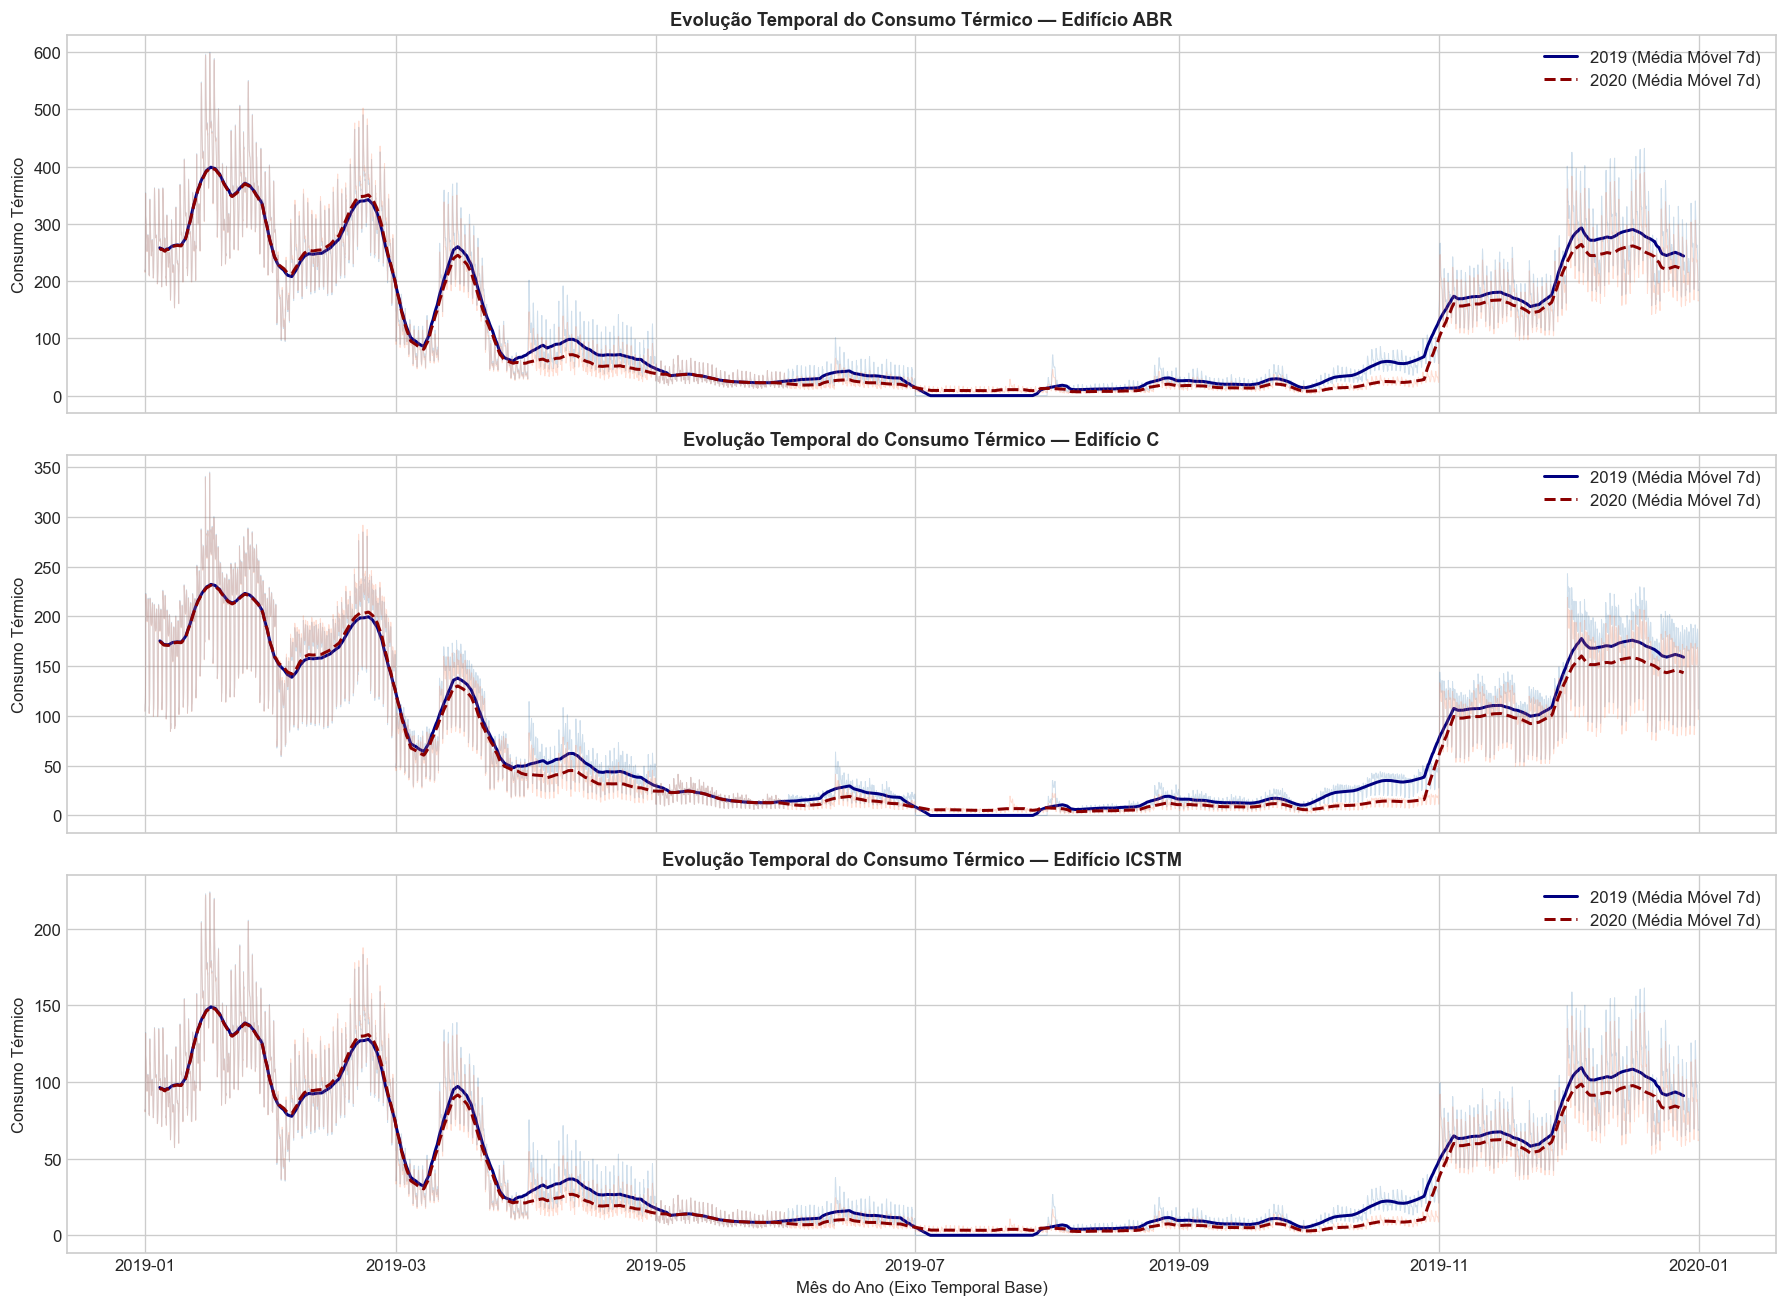

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)

for idx, (edificio, df) in enumerate(dfs.items()):
    col19 = f'heat_{edificio}_2019'
    col20 = f'heat_{edificio}_2020'
    
    axes[idx].plot(df['datetime_base'], df[col19], color='steelblue', alpha=0.25, linewidth=0.6)
    axes[idx].plot(df['datetime_base'], df[col19].rolling(168, center=True).mean(),
                   color='navy', linewidth=1.8, label='2019 (Média Móvel 7d)')
    
    axes[idx].plot(df['datetime_base'], df[col20], color='coral', alpha=0.25, linewidth=0.6)
    axes[idx].plot(df['datetime_base'], df[col20].rolling(168, center=True).mean(),
                   color='darkred', linewidth=1.8, linestyle='--', label='2020 (Média Móvel 7d)')
    
    axes[idx].set_title(f'Evolução Temporal do Consumo Térmico — Edifício {edificio}', fontsize=11, fontweight='bold')
    axes[idx].set_ylabel('Consumo Térmico')
    axes[idx].legend(loc='upper right')

axes[-1].set_xlabel('Mês do Ano (Eixo Temporal Base)')
plt.tight_layout()
plt.show()

---
## 4. Distribuição e Variabilidade do Consumo

Os histogramas e diagramas de extremos e quartis (*boxplots*) confirmam a natureza **bimodal / assimétrica positiva** dos dados:
* Existe uma grande concentração de horas com consumo muito baixo (correspondente aos meses de primavera/verão e períodos noturnos).
* Uma cauda longa estende-se para valores elevados (horas de ponta nos meses de inverno).
* Nos *boxplots* mensais, verifica-se também que **a variabilidade (amplitude interquartil) aumenta proporcionalmente ao nível de consumo**: no inverno, além de a mediana ser elevada, existem oscilações muito acentuadas entre o dia e a noite.

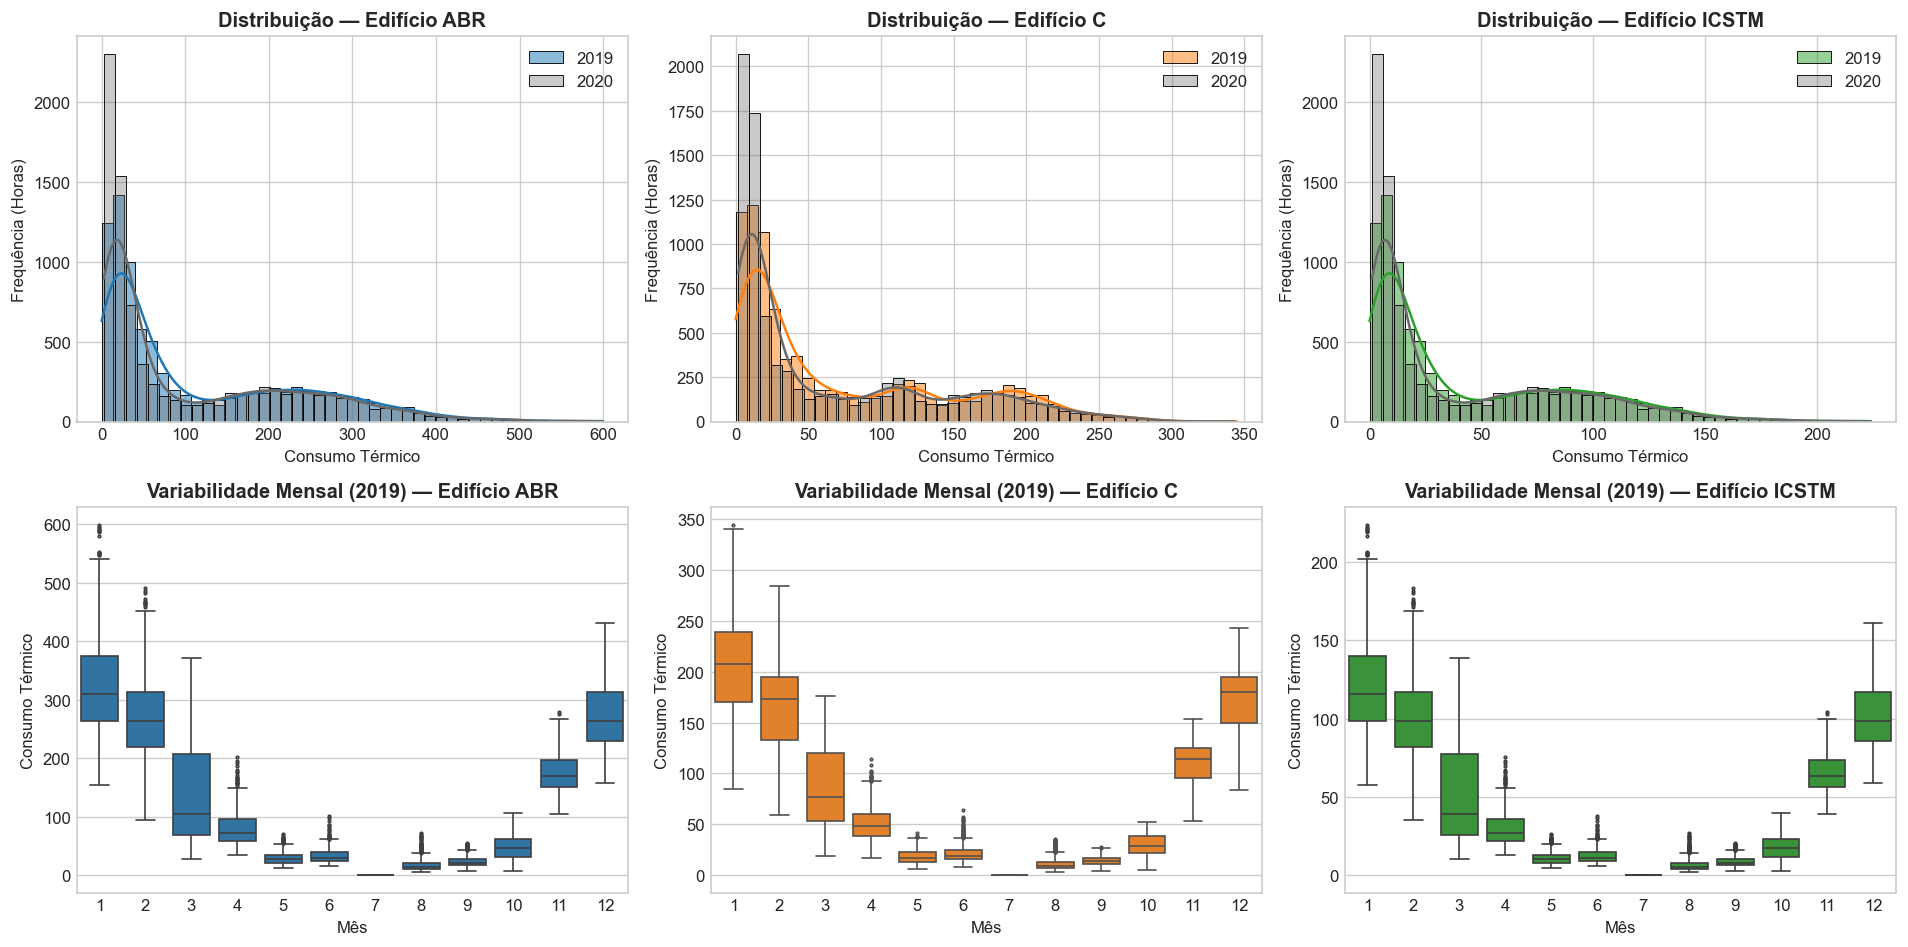

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

cores = ['#1f77b4', '#ff7f0e', '#2ca02c']

for idx, (edificio, df) in enumerate(dfs.items()):
    col19 = f'heat_{edificio}_2019'
    col20 = f'heat_{edificio}_2020'
    
    sns.histplot(df[col19], bins=45, kde=True, ax=axes[0, idx], color=cores[idx], alpha=0.5, label='2019')
    sns.histplot(df[col20], bins=45, kde=True, ax=axes[0, idx], color='dimgray', alpha=0.35, label='2020')
    axes[0, idx].set_title(f'Distribuição — Edifício {edificio}', fontweight='bold')
    axes[0, idx].set_xlabel('Consumo Térmico')
    axes[0, idx].set_ylabel('Frequência (Horas)')
    axes[0, idx].legend()
    
    sns.boxplot(data=df, x='mes', y=col19, ax=axes[1, idx], color=cores[idx], fliersize=1.5)
    axes[1, idx].set_title(f'Variabilidade Mensal (2019) — Edifício {edificio}', fontweight='bold')
    axes[1, idx].set_xlabel('Mês')
    axes[1, idx].set_ylabel('Consumo Térmico')

plt.tight_layout()
plt.show()

---
## Análise Quantitativa de Valores Atípicos (*Outliers*)

Aplicando o critério estatístico do **Intervalo Interquartil (IQR)** ($Q_3 + 1.5 \times \text{IQR}$), observa-se que a percentagem de valores atípicos é residual em todas as séries (inferior a **0,75%** do total de registos horários):
* **Edifícios ABR e ICSTM:** Apresentam exatamente a mesma proporção de *outliers* (**0,43%** em 2019 e **0,73%** em 2020), confirmando que partilham perfis de consumo proporcionais entre si.
* **Edifício C:** Regista a menor incidência de valores extremos (**0,14%** em 2019 e **0,41%** em 2020).
* **Interpretação Física (Relevância para a Modelação):** Todos os valores atípicos situam-se acima do limite superior e correspondem a **picos reais de procura térmica** nas manhãs mais frias de inverno (e não a falhas de leitura), pelo que **não devem ser removidos** na etapa de preparação dos dados (Ponto 4.2), uma vez que o modelo de previsão precisa de aprender a antecipar estes picos de consumo.

In [ ]:
resumo_outliers = []

for edificio, df in dfs.items():
  for col in [c for c in df.columns if 'heat' in c]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr

    outliers = df[(df[col] < limite_inf) | (df[col] > limite_sup)]

    resumo_outliers.append({
        'Edifício': edificio,
        'Variável': col,
        'Limite Superior (Q3 + 1.5*IQR)': round(limite_sup, 2),
        'Nº Outliers': len(outliers),
        '% do Total': round(len(outliers) / len(df) * 100, 2),
        'Valor Máximo': round(df[col].max(), 2),
    })

display(pd.DataFrame(resumo_outliers))

,Edifício,Variável,Limite Superior (Q3 + 1.5*IQR),Nº Outliers,% do Total,Valor Máximo
0,ABR,heat_ABR_2019,485.60,38,0.43,599.66
1,ABR,heat_ABR_2020,465.94,64,0.73,597.36
2,C,heat_C_2019,286.38,12,0.14,345.00
3,C,heat_C_2020,274.62,36,0.41,343.67
4,ICSTM,heat_ICSTM_2019,181.49,38,0.43,224.12
5,ICSTM,heat_ICSTM_2020,174.14,64,0.73,223.26


---
## 5. Padrões Diários, Semanais e Sazonais

A análise multidimensional por **hora do dia**, **dia da semana** e **mês do ano** permite extrair conclusões essenciais para a engenharia de atributos (Ponto 4.2):
1. **Padrão Diário (Ciclo de 24h):** O consumo térmico não é constante ao longo do dia. Apresenta um **pico pronunciado nas primeiras horas da manhã (entre as 05h00 e as 09h00)** — altura em que os sistemas AVAC/caldeiras arrancam para pré-aquecer as salas antes do início das aulas — seguido de uma estabilização durante o dia e uma queda gradual ao final da tarde e noite.
2. **Padrão Semanal (Dias Úteis vs. Fim de Semana):** Nos dias úteis (segunda a sexta-feira), o consumo matinal é significativamente superior ao registado aos sábados e domingos, refletindo a programação horária da ocupação académica.
3. **Interação Hora $\times$ Mês (Mapa de Calor):** O *heatmap* demonstra que o ciclo diário é muito intenso de novembro a março, enquanto nos meses de verão (junho a agosto) o consumo permanece quase plano e próximo do mínimo durante as 24 horas.

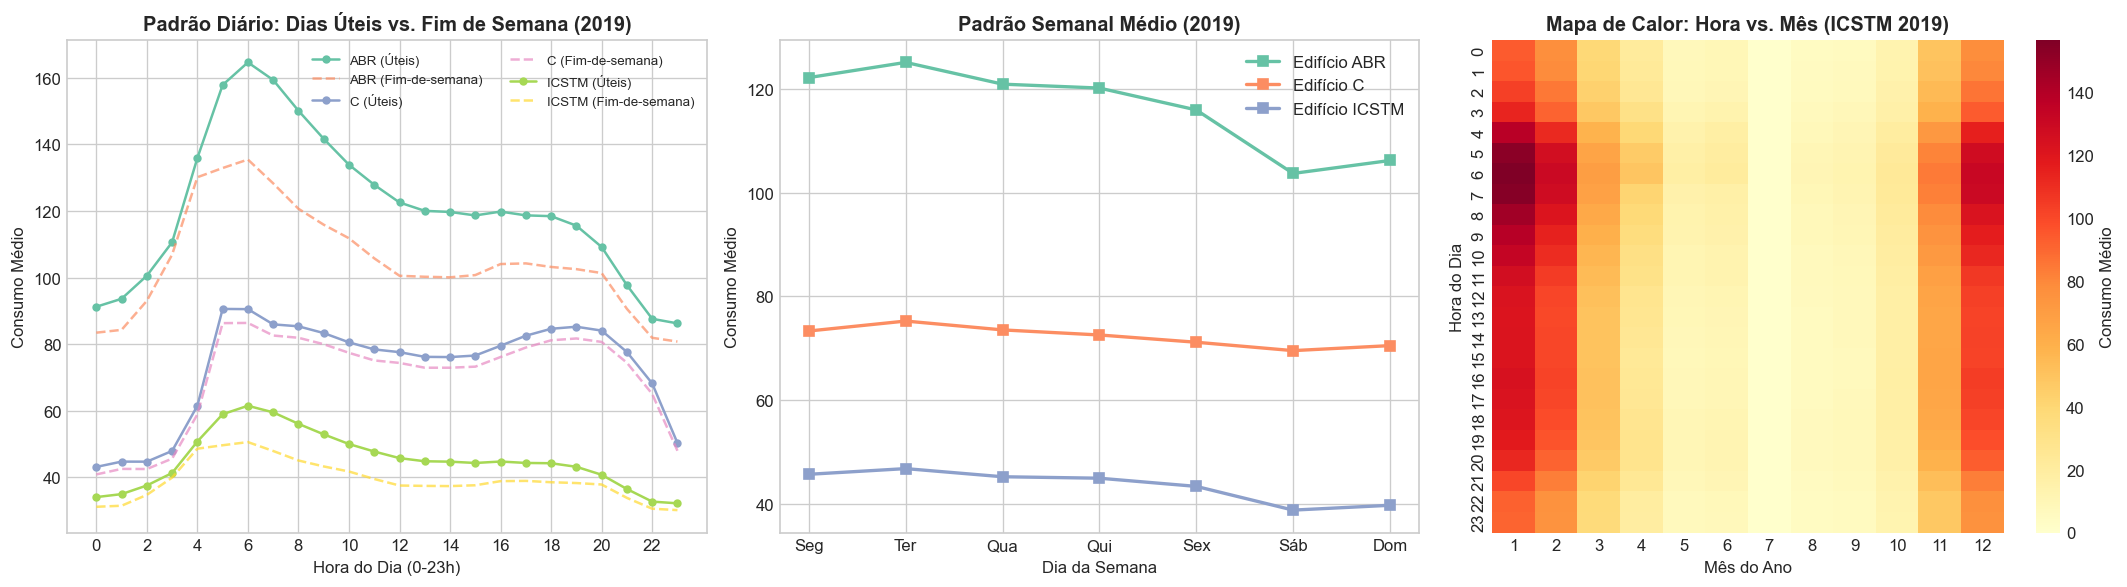

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

dias_nomes = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']

for edificio, df in dfs.items():
    col19 = f'heat_{edificio}_2019'
    perfil_uteis = df[~df['fim_de_semana']].groupby('hora')[col19].mean()
    perfil_fds = df[df['fim_de_semana']].groupby('hora')[col19].mean()
    axes[0].plot(perfil_uteis.index, perfil_uteis.values, marker='o', markersize=4, label=f'{edificio} (Úteis)')
    axes[0].plot(perfil_fds.index, perfil_fds.values, linestyle='--', alpha=0.7, label=f'{edificio} (Fim-de-semana)')

axes[0].set_title('Padrão Diário: Dias Úteis vs. Fim de Semana (2019)', fontweight='bold')
axes[0].set_xlabel('Hora do Dia (0-23h)')
axes[0].set_ylabel('Consumo Médio')
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend(fontsize=8, ncol=2)

for edificio, df in dfs.items():
    col19 = f'heat_{edificio}_2019'
    perfil_sem = df.groupby('dia_semana')[col19].mean()
    axes[1].plot(dias_nomes, perfil_sem.values, marker='s', linewidth=2, label=f'Edifício {edificio}')

axes[1].set_title('Padrão Semanal Médio (2019)', fontweight='bold')
axes[1].set_xlabel('Dia da Semana')
axes[1].set_ylabel('Consumo Médio')
axes[1].legend()

pivot_icstm = dfs['ICSTM'].pivot_table(index='hora', columns='mes', values='heat_ICSTM_2019', aggfunc='mean')
sns.heatmap(pivot_icstm, cmap='YlOrRd', ax=axes[2], cbar_kws={'label': 'Consumo Médio'})
axes[2].set_title('Mapa de Calor: Hora vs. Mês (ICSTM 2019)', fontweight='bold')
axes[2].set_xlabel('Mês do Ano')
axes[2].set_ylabel('Hora do Dia')

plt.tight_layout()
plt.show()

---
## 6. Identificação de Períodos de Consumo Elevado e Reduzido

Para apoiar o planeamento energético (objetivo do projeto), identificamos quantitativamente os meses e horas de maior e menor procura térmica:
* **Períodos de Consumo Elevado (Ponta Térmica):** Ocorrem nos meses de **janeiro, fevereiro e dezembro**, especialmente no período matinal (**06h00 às 10h00**), quando a temperatura exterior é mais baixa e a inércia térmica dos edifícios exige maior potência de aquecimento.
* **Períodos de Consumo Reduzido (Vale Térmico):** Ocorrem entre **junho e agosto** (verão e férias letivas) e durante a **madrugada (00h00 às 04h00)** nos meses intermédios.

In [ ]:
meses_pt = {
    1: 'Jan',
    2: 'Fev',
    3: 'Mar',
    4: 'Abr',
    5: 'Mai',
    6: 'Jun',
    7: 'Jul',
    8: 'Ago',
    9: 'Set',
    10: 'Out',
    11: 'Nov',
    12: 'Dez',
}

for edificio, df in dfs.items():
  col19 = f'heat_{edificio}_2019'
  media_mensal = df.groupby('mes')[col19].mean()
  media_horaria = df.groupby('hora')[col19].mean()

  top3_meses = [
      f'{meses_pt[m]} ({v:.1f})' for m, v in media_mensal.nlargest(3).items()
  ]
  bot3_meses = [
      f'{meses_pt[m]} ({v:.1f})' for m, v in media_mensal.nsmallest(3).items()
  ]
  hora_pico = media_horaria.idxmax()
  hora_vale = media_horaria.idxmin()

  print(f'=== Edifício {edificio} (2019) ===')
  print(f"  • Top 3 Meses Maior Consumo : {', '.join(top3_meses)}")
  print(f"  • Top 3 Meses Menor Consumo : {', '.join(bot3_meses)}")
  print(
      f'  • Hora Média de Pico Diário : {hora_pico:02d}:00h'
      f' ({media_horaria.max():.2f})'
  )
  print(
      f'  • Hora Média de Vale Diário : {hora_vale:02d}:00h'
      f' ({media_horaria.min():.2f})'
  )
  print()

=== Edifício ABR (2019) ===
  • Top 3 Meses Maior Consumo : Jan (325.3), Dez (272.3), Fev (267.9)
  • Top 3 Meses Menor Consumo : Jul (0.0), Ago (17.7), Set (22.3)
  • Hora Média de Pico Diário : 06:00h (156.28)
  • Hora Média de Vale Diário : 23:00h (84.69)

=== Edifício C (2019) ===
  • Top 3 Meses Maior Consumo : Jan (202.0), Dez (169.1), Fev (166.4)
  • Top 3 Meses Menor Consumo : Jul (0.0), Ago (11.0), Set (13.9)
  • Hora Média de Pico Diário : 05:00h (89.37)
  • Hora Média de Vale Diário : 00:00h (42.52)

=== Edifício ICSTM (2019) ===
  • Top 3 Meses Maior Consumo : Jan (121.6), Dez (101.8), Fev (100.1)
  • Top 3 Meses Menor Consumo : Jul (0.0), Ago (6.6), Set (8.3)
  • Hora Média de Pico Diário : 06:00h (58.41)
  • Hora Média de Vale Diário : 23:00h (31.65)



---
## Síntese para o Relatório Técnico

1. **Correlação entre Edifícios:** Os edifícios `ABR`, `C` e `ICSTM` partilham exatamente a mesma dinâmica sazonal e diária, diferindo apenas na **magnitude do consumo** (`ABR > C > ICSTM`), proporcional à sua dimensão e necessidades térmicas.
2. **Forte Sazonalidade (Consumo Elevado no Inverno vs. Restantes Estações):** Nos meses de inverno (**janeiro, fevereiro e dezembro**), o consumo médio térmico dispara para valores entre **17 a 20 vezes superiores** aos registados no verão (por exemplo, no edifício `ABR`, a média no inverno ronda os ~289 kWh em 2019 e ~281 kWh em 2020, face a ~14–17 kWh no verão). Este comportamento confirma que a procura energética está diretamente dependente da temperatura exterior e da necessidade de climatização dos espaços letivos.
3. **Importância das Variáveis Temporais (Ligação ao Ponto 4.2):** A forte dependência da **hora do dia** (picos matinais entre as 06h00 e as 10h00), do **dia da semana** (dias úteis vs. fim de semana) e do **mês do ano** justifica plenamente a inclusão destas variáveis temporais — bem como de valores históricos (*lags* de 1h, 24h e 168h) — nos modelos de Aprendizagem Profunda.
4. **Preservação dos Valores Atípicos (*Outliers*):** Os valores detetados acima do limite superior do IQR ($<0,75\%$ dos registos) não constituem erros de medição, mas sim **picos reais de procura térmica** nas manhãs mais rigorosas de inverno. Por esse motivo, **não deverão ser eliminados** na preparação dos dados (Ponto 4.2), garantindo que as redes neuronais aprendem a prever situações de ponta energética.
5. **Atenção aos Dados de 2019:** Na fase de preparação dos dados, deve ter-se em conta que o mês de **julho de 2019** apresenta `0.0` em todas as 744 horas nos três edifícios (possível paragem técnica ou falha de registo), enquanto a série de 2020 é contínua sem zeros absolutos.